# Master Analysis — Optimal Risk Geometry by Prop Firm

**A probability + risk-geometry problem.** You choose only three things:
a **strategy** (entry logic), a **data file** (your ES/NQ 1-min parquet), and a
**firm**. Everything else is discovered:

* **R:R** — swept; the win rate at each R:R is *measured from your data*.
* **Risk %** — searched by the Monte Carlo (interior optimum for trailing DD firms).
* **Trades/day** — emergent (whole trading days are resampled from the ledger).

No predefined exit, R:R, or risk. Run top to bottom.


In [1]:
import os, sys

# Search for the folder that actually contains Firms.py, starting from a base
# and walking every subfolder. Edit SEARCH_ROOT if your project lives elsewhere.
SEARCH_ROOT = r"C:\Users\2115h\Desktop\Trading"

PROJECT_DIR = None
for root, dirs, files in os.walk(SEARCH_ROOT):
    if "__pycache__" in root:
        continue
    if "Firms.py" in files:
        PROJECT_DIR = root
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        f"Could not find Firms.py anywhere under {SEARCH_ROOT}. "
        "Fix SEARCH_ROOT to point at your project.")

os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
print("Found project at:", PROJECT_DIR)
print("Files here:", [f for f in os.listdir(PROJECT_DIR) if f.endswith(".py")])


Found project at: C:\Users\2115h\Desktop\Trading\Propfirm Convex Analysis\Rules
Files here: ['Analysis.py', 'Backtest.py', 'Engine.py', 'Firms.py', 'Run.py', 'Strategy.py']


In [ ]:
# --- Setup (robust path for Jupyter & VS Code) ---
import os, sys
def _find_project():
    cands = []
    if "__vsc_ipynb_file__" in globals():
        cands.append(os.path.dirname(globals()["__vsc_ipynb_file__"]))
    cands += [os.getcwd(), os.path.dirname(os.getcwd())]
    for d in cands:
        if os.path.exists(os.path.join(d, "Firms.py")):
            return d
    return None
PROJECT_DIR = _find_project() or os.getcwd()
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from Firms import FIRMS, get_firm
from Strategy import EmpiricalStrategy
from Backtest import build_entries, ledger_for_rr, measured_winrate
from Analysis import (measured_wr_curve, plot_risk_curve, find_optimal_risk,
                      risk_rr_heatmap, optimal_geometry, optimal_risk_by_firm,
                      plot_equity_paths)

# ============ THE ONLY CHOICES ============
STRATEGY  = "new_jj"                       # match the filename (lowercase)
DATA_PATH = "data/NQ.OHLCV_1min.csv"
FIRM      = get_firm("topstep")
RTH_ONLY  = False                          # new_jj needs full-session data
TIMEFRAME = "3min"
SWING_K   = 8
RR_GRID   = [0.5, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 2.75, 3.0]
RISK_PCTS = np.round(np.arange(0.25, 3.51, 0.25), 2)

K_STOP_ATR_GRID = [1, 2, 3, 5, 7, 10]      # <-- the sweep
# ==========================================

Project dir: C:\Users\2115h\Desktop\Trading\Propfirm Convex Analysis\Rules


In [21]:
# --- Sweep K_STOP_ATR: how stop width affects pass rate for this firm ---
rows = []
for kstop in K_STOP_ATR_GRID:
    E = build_entries(STRATEGY, DATA_PATH, rth_only=RTH_ONLY, timeframe=TIMEFRAME,
                      swing_k=SWING_K, k_stop_atr=kstop)
    n = len(E.day_ids)
    if n < 100:
        print(f"K_STOP_ATR={kstop}: only {n} trades — skipping"); continue
    wr1 = (ledger_for_rr(E, 1.0)[0] > 0).mean()
    g = optimal_geometry(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                         n_paths=1500, max_trades=300)
    rows.append((kstop, n, wr1*100, g['opt_rr'], g['opt_risk_pct'], g['opt_pass_pct'], g['opt_speed']))

print(f"\n{'K_STOP':>6}{'trades':>8}{'WR@1R':>7}{'bestRR':>7}{'risk%':>7}{'pass%':>7}{'trades_to_pass':>16}")
for r in sorted(rows, key=lambda x: -x[5]):
    print(f"{r[0]:>6}{r[1]:>8}{r[2]:>6.0f}%{r[3]:>7g}{r[4]:>7.2f}{r[5]:>6.0f}%{r[6]:>16.0f}")

# quick plot of pass rate vs stop width
if rows:
    ks = [r[0] for r in rows]; pp = [r[5] for r in rows]
    plt.figure(figsize=(8,4)); plt.plot(ks, pp, "-o")
    plt.xlabel("K_STOP_ATR (stop width in ATRs)"); plt.ylabel("Best pass rate (%)")
    plt.title(f"Pass rate vs stop width — {FIRM.name} [{STRATEGY}]"); plt.grid(alpha=.3); plt.show()

ModuleNotFoundError: No module named 'strategies.new_jj'

## Firm rules ($50K)

In [4]:
for k, f in FIRMS.items():
    print(f"{k:17s} {f.name:26s} dd={f.dd_type.value:14s} lock={str(f.trail_lock):7s} "
          f"DLL={str(f.daily_loss_limit):5s}({f.dll_behavior.value:4s}) "
          f"cons={str(f.consistency_pct):4s} min_days={f.min_days}")


apex_eod          Apex (EOD Trailing)        dd=eod_trail      lock=50000   DLL=1000 (hard) cons=None min_days=1
apex_intraday     Apex (Intraday Trailing)   dd=intraday_trail lock=50000   DLL=None (none) cons=None min_days=1
lucid             Lucid (LucidPro)           dd=eod_trail      lock=50000   DLL=1200 (hard) cons=None min_days=1
tradeify_select   Tradeify (Select)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.4  min_days=3
tradeify_growth   Tradeify (Growth)          dd=eod_trail      lock=50000   DLL=1250 (soft) cons=None min_days=1
mffu_rapid        MyFundedFutures (Rapid)    dd=intraday_trail lock=None    DLL=None (none) cons=0.5  min_days=2
topstep           Topstep (Combine)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.5  min_days=2


In [3]:
import strategies.bos as b, inspect
print(inspect.getfile(b))                                   # which bos.py is loaded
print("swing_k default:", inspect.signature(b.BOS.__init__)) # new file shows trend_ema, min_break_atr...
print("has _atr filter:", hasattr(b, "_atr"))                # True only for the new file

C:\Users\2115h\Desktop\Trading\Propfirm Convex Analysis\Rules\strategies\bos.py
swing_k default: (self, swing_k=8, trend_ema=200, min_break_atr=0.1, adx_min=0.0, cooldown=0, atr_period=14)
has _atr filter: True


## 1) Backtest entries and MEASURE win rate by R:R

Loads the strategy + data, runs entries, walks each forward once. Trades/day is
emergent (printed). Win rate at each R:R is how often price hit that target
before the 1R stop — measured, not assumed.

310 entries over 294 days (~1.05 trades/day) | new_jj on NQ.OHLCV_1min.csv


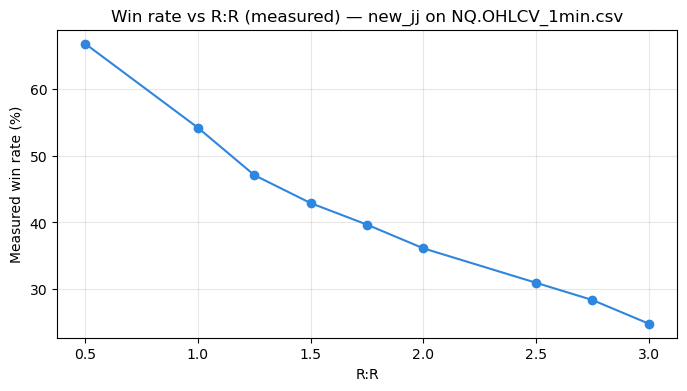

  0.5R  WR=66.8%   edge=+0.002R
  1.0R  WR=54.2%   edge=+0.084R
  1.25R  WR=47.1%   edge=+0.074R
  1.5R  WR=42.9%   edge=+0.097R
  1.75R  WR=39.7%   edge=+0.139R
  2.0R  WR=36.1%   edge=+0.158R
  2.5R  WR=31.0%   edge=+0.201R
  2.75R  WR=28.4%   edge=+0.221R
  3.0R  WR=24.8%   edge=+0.236R


In [13]:
E = build_entries(STRATEGY, DATA_PATH, rth_only=True, timeframe=TIMEFRAME,
                  swing_k=SWING_K, k_stop_atr=K_STOP_ATR)
print(E.summary())
fig, wr_by_rr, edge_by_rr = measured_wr_curve(E, RR_GRID); plt.show()
for rr in RR_GRID:
    print(f"  {rr:>3}R  WR={wr_by_rr[rr]:5.1%}   edge={edge_by_rr[rr]:+.3f}R")


## 2) Optimal risk geometry for the chosen firm

Rows = risk %, columns = R:R. Colour = pass rate, second number = trades to pass.
The title reports the single best (R:R, risk%) cell — the geometry this firm
rewards for this strategy.

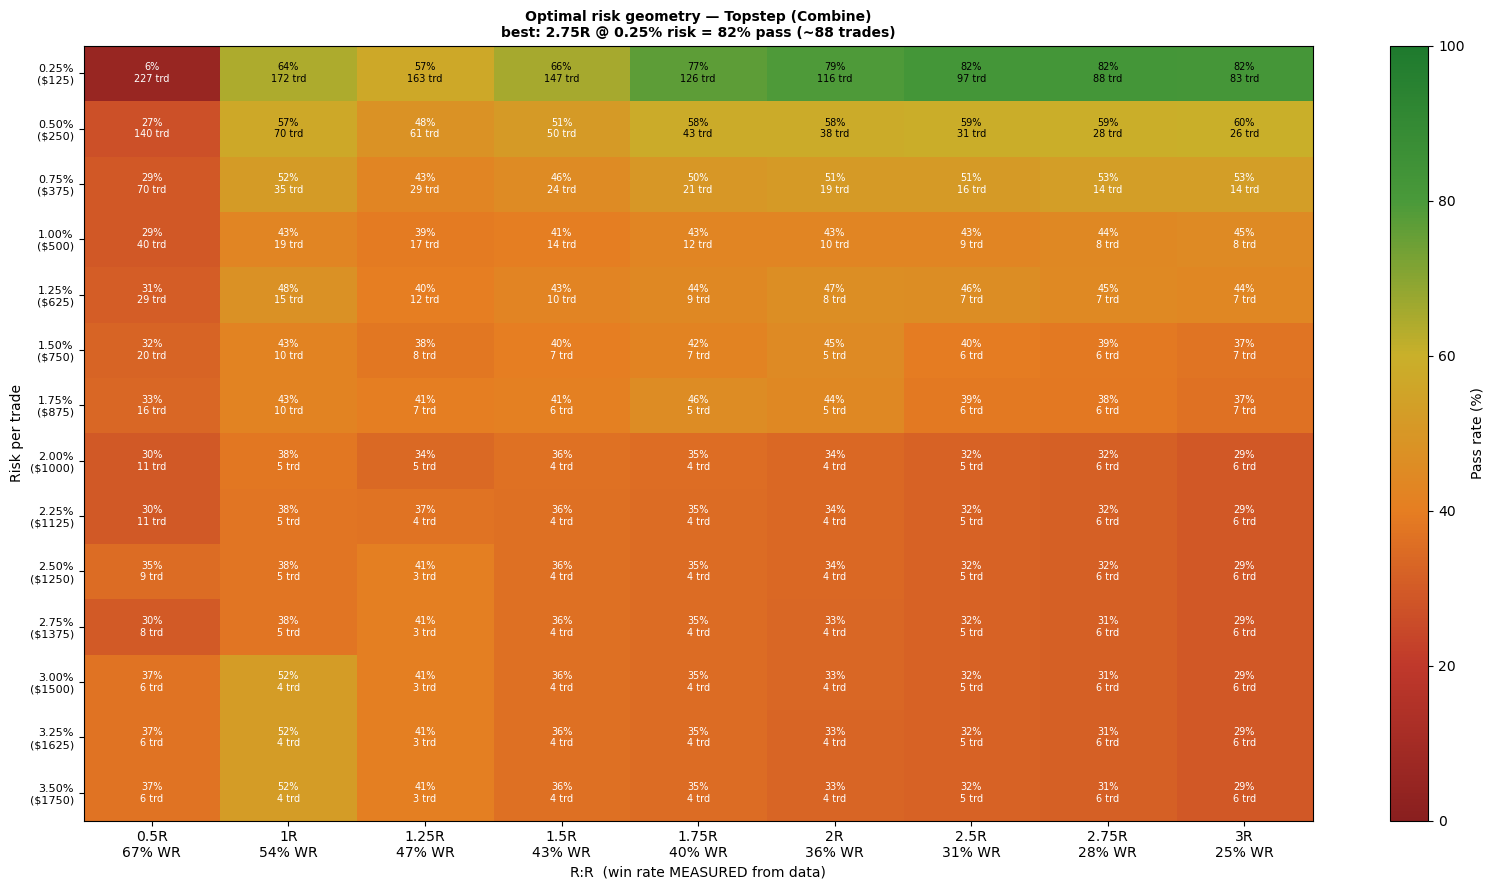

BEST for Topstep (Combine): 2.75R @ 0.25% risk ($125/trade) -> 82% pass in ~88 trades (measured WR 28%)


In [15]:
fig, g = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                         n_paths=2000, max_trades=300); plt.show()
print(f"BEST for {FIRM.name}: {g['opt_rr']:g}R @ {g['opt_risk_pct']:.2f}% risk "
      f"(${FIRM.start_balance*g['opt_risk_pct']/100:.0f}/trade) -> "
      f"{g['opt_pass_pct']:.0f}% pass in ~{g['opt_speed']:.0f} trades "
      f"(measured WR {g['opt_wr']:.0%})")


## 3) Risk curve at the optimal R:R

Zoom in on the winning R:R and show the full pass-rate-vs-risk curve, with the
discovered optimum marked.

In [19]:
from Backtest import load_ohlc, backtest_entries
from New_jj import New_JJ

bars = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")  # 1-min, full session
# bars = bars.loc["2025-01-01":"2026-12-31"]   # <-- uncomment for your 2025–2026 test
E = backtest_entries(NewJJ(bos_tf="3min"), bars, k_stop_atr=K_STOP_ATR, max_hold=60)
print(E.summary())
fig, wr_by_rr, edge_by_rr = measured_wr_curve(E, RR_GRID); plt.show()
for rr in RR_GRID:
    print(f"  {rr:>3}R  WR={wr_by_rr[rr]:5.1%}   edge={edge_by_rr[rr]:+.3f}R")

ModuleNotFoundError: No module named 'New_jj'

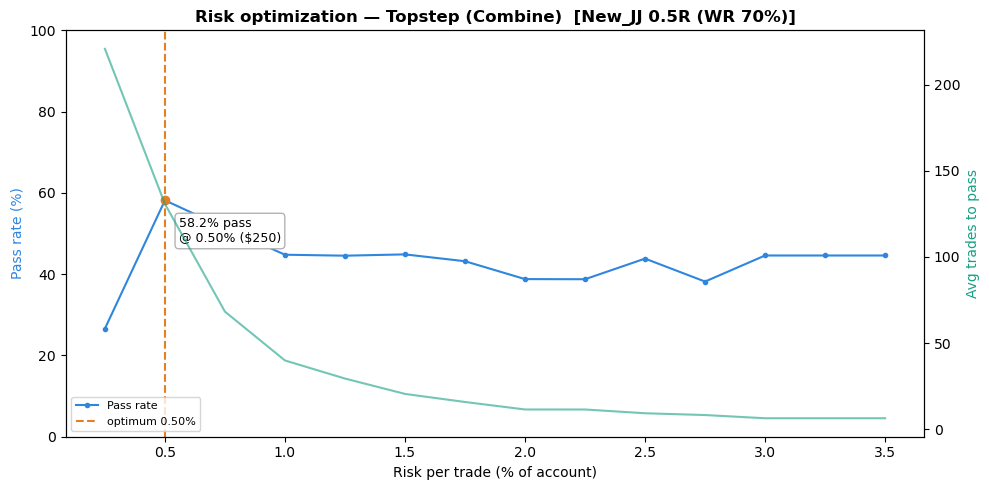

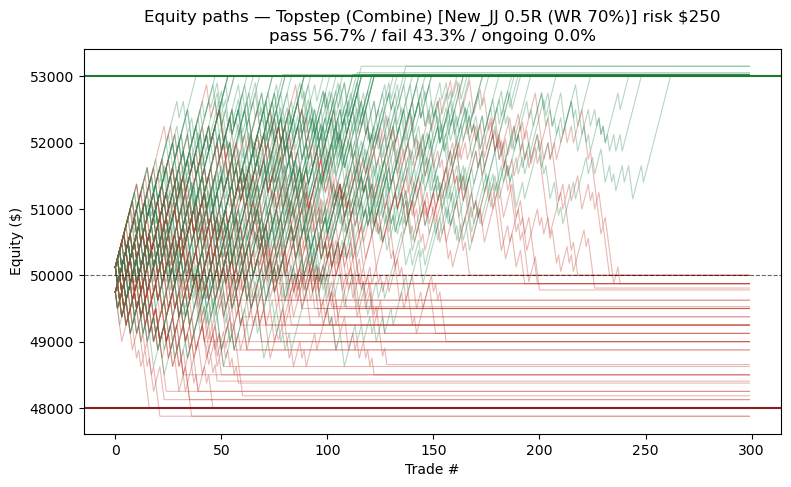

In [8]:
R, days = ledger_for_rr(E, g["opt_rr"])
strat = EmpiricalStrategy(R, name=f"{STRATEGY} {g['opt_rr']:g}R "
                          f"(WR {measured_winrate(E, g['opt_rr']):.0%})", day_ids=days)
fig, r = plot_risk_curve(strat, FIRM, risk_pcts=RISK_PCTS, n_paths=3000, max_trades=300)
plt.show()

fig = plot_equity_paths(FIRM, strat, risk_per_trade=r["opt_risk_dollars"],
                        n_show=120, max_trades=300); plt.show()
                        


## 4) Cross-firm: best pass rate & the risk that achieves it

Same strategy at its optimal R:R, optimal risk discovered per firm. The "different
game per firm" result, fully data-driven.

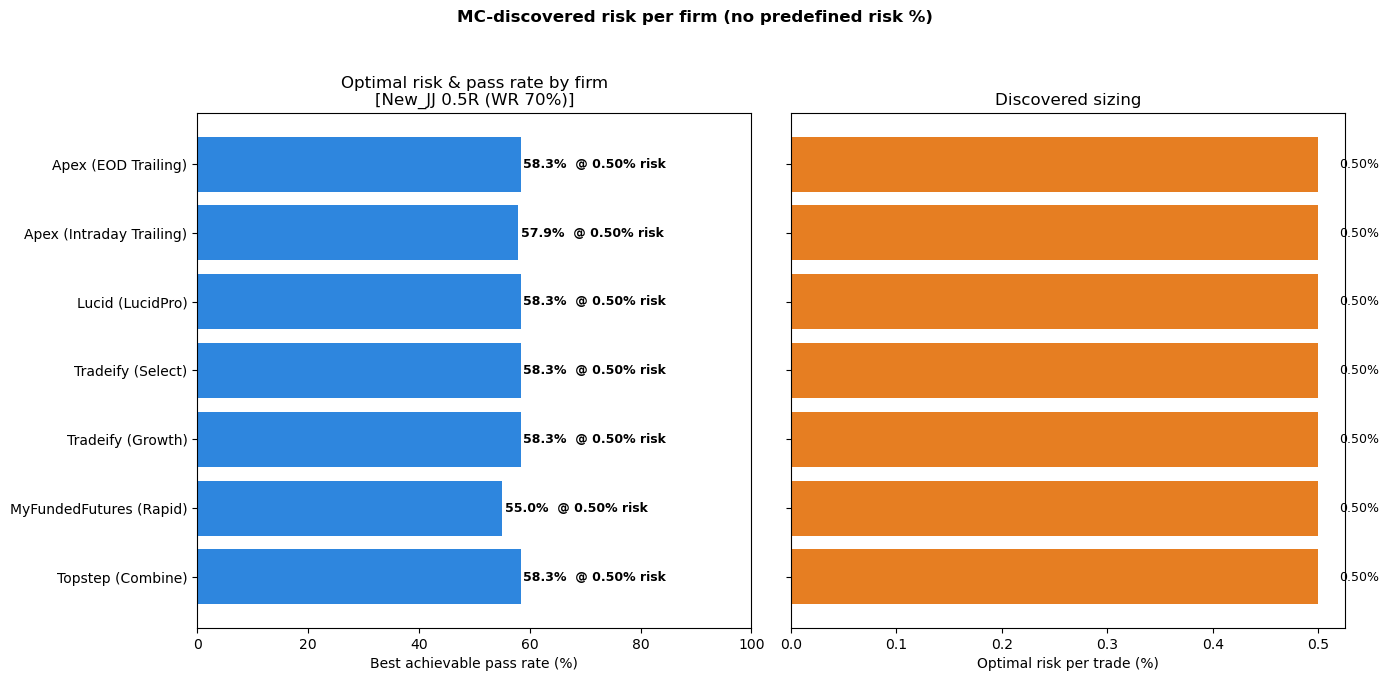

In [9]:
results, fig = optimal_risk_by_firm(
    strat, get_firm,
    ["apex_eod","apex_intraday","lucid","tradeify_select",
     "tradeify_growth","mffu_rapid","topstep"],
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300)
plt.show()


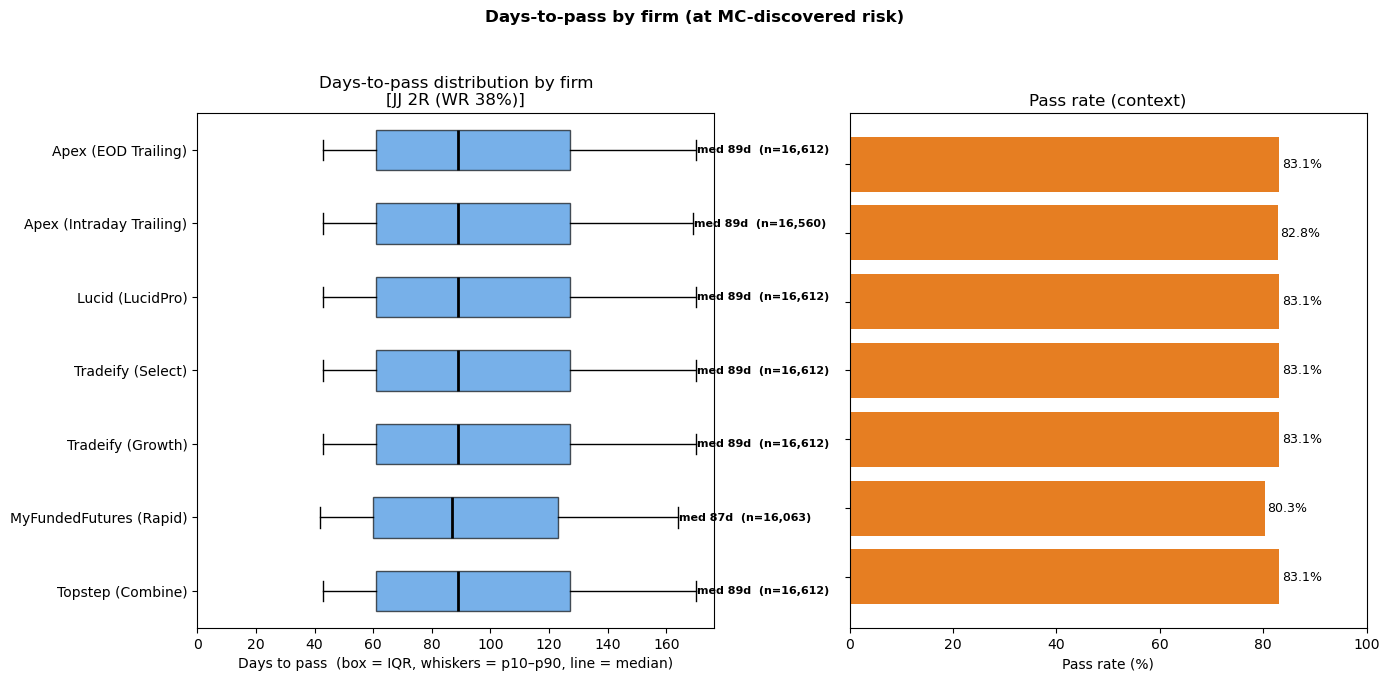

In [8]:
from Analysis import days_to_pass_by_firm
results, fig, summary = days_to_pass_by_firm(
    strat, get_firm,
    ["apex_eod","apex_intraday","lucid","tradeify_select",
     "tradeify_growth","mffu_rapid","topstep"],
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300, dist_paths=20000)
plt.show()   # <-- parentheses

## Add your ES / NQ data / another strategy

* **Data:** drop `ES_1min.parquet` in `data/`, set `DATA_PATH = "data/ES_1min.parquet"`,
  re-run. `RTH_ONLY=True` for regular session; `TIMEFRAME="5min"` for higher TF.
* **Strategy:** add `strategies/<name>.py` with an `EntryStrategy` subclass and a
  `get_strategy()`. Set `STRATEGY = "<name>"`. (BOS `_fired` is reproduced in
  `strategies/bos.py` — no external repo needed.)
* **Firm:** change `FIRM = get_firm("topstep")` etc.

Nothing else changes — measured WR, optimal risk, the heatmap, and the cross-firm
chart all recompute from your inputs.